# CVAE — Arquitectura B (Provincia-Dia)

Una muestra = un dia de **una sola provincia**, no del sistema completo: `x` es un vector de 24 dimensiones (el perfil horario de esa provincia) y `c` combina el clima de esa provincia, el calendario, e indicadores socioeconomicos (poblacion, PBG per capita, participacion industrial, superficie), que aca si varian entre muestras porque cada fila corresponde a una provincia distinta.

El modelo aprende una regla general: alta poblacion + industria implica alta demanda.

**Importante — no es directamente comparable con los modelos dia-sistema (CVAE-A, VAE sin condicion, Conditional KDE)**:

- Esos tres modelan el vector de 528 dimensiones (22 provincias x 24 horas) de un dia completo del sistema; CVAE-B modela 24 dimensiones de una sola provincia por muestra.
- CVAE-B **no genera las 22 provincias de forma conjunta en una misma muestra** — cada generacion es independiente por provincia, no captura correlaciones entre provincias el mismo dia (que es justamente lo que CVAE-A intenta capturar implicitamente a traves de la estructura de `x`).
- Por el cambio de escala y de unidad de muestra, **el MMD de CVAE-B no vive en el mismo espacio** que el de VAE, KDE o CVAE-A, y no deberia compararse directamente entre ellos.
- Si estos resultados se incluyen en la tabla final del informe, hay que marcar a CVAE-B explicitamente como **arquitectura alternativa**, con una nota debajo de la tabla aclarando que sus metricas se calculan en un espacio de 24 dimensiones provincia-dia, mientras que las de CVAE-A, KDE y VAE se calculan en 528 dimensiones dia-sistema.

Este notebook se entiende mejor como un **experimento complementario**: ¿ayuda modelar cada provincia por separado, con sus propios indicadores socioeconomicos, a calibrar mejor los perfiles locales que un unico modelo conjunto?

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import pickle
import json
import matplotlib.pyplot as plt
import torch

project_root = Path.cwd().parent
sys.path.append(str(project_root / 'src'))

from preprocessing_b import run_preprocessing_b
from cvae import CVAE
from train_cvae import train, set_seed
from evaluate_cvae import full_evaluation, generate_scenarios, posterior_prior_gap

SPLITS_DIR  = project_root / 'data' / 'splits'
PROCESSED_DIR = project_root / 'data' / 'processed'
RESULTS_DIR = project_root / 'results' / 'cvae_b'
RESULTS_DIR.mkdir(exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

Device: cpu


## 1. Preprocessing Architecture B

Este preprocessing (`run_preprocessing_b`, en `preprocessing_b.py`) es **especifico de la Arquitectura B** — convierte `x` de formato ancho (1 fila por dia, 528 columnas) a formato largo (1 fila por provincia-dia, 24 columnas), y arma `c` uniendo clima provincial, calendario e indicadores socioeconomicos por provincia. No es el mismo preprocessing que usan CVAE-A, VAE o KDE (esos usan los arrays ya armados en `data/splits/`); este notebook lo corre de punta a punta cada vez.

Construimos el dataset en formato provincia-dia. El split temporal se hace por fecha — no por provincia — y se conserva correctamente: cada fecha cae en un unico split (train/val/test), y todas las provincias de esa fecha quedan en el mismo split.

In [3]:
data_b = run_preprocessing_b(
    processed_dir=PROCESSED_DIR,
    save_dir=SPLITS_DIR,
)

X_train = data_b['X_train']
X_val   = data_b['X_val']
X_test  = data_b['X_test']
C_train = data_b['C_train']
C_val   = data_b['C_val']
C_test  = data_b['C_test']

provinces_test = data_b['provinces_test']
x_scaler_b     = data_b['x_scaler']

print(f'X_train: {X_train.shape}, C_train: {C_train.shape}')
print(f'x_dim={X_train.shape[1]}, c_dim={C_train.shape[1]}')

x_wide:      (2311, 529)
clima:       (50842, 14)
calendario:  (2311, 4)
indicadores: (22, 5)

x_long: (50842, 26)  (50842 province-day samples)
c_long: (50842, 21)

Despues de eliminar dias anomalos: 50776 samples

Split:
  train: 32054 samples (1457 dias × 22 provincias)
  val:   8052 samples
  test:  10670 samples

Shapes finales:
  X_train: (32054, 24), X_val: (8052, 24), X_test: (10670, 24)
  C_train: (32054, 19), C_val: (8052, 19), C_test: (10670, 19)
  x_dim: 24, c_dim: 19

Archivos guardados en c:\Users\pazbi\OneDrive\Escritorio\ml\tp_final_ml\provincias\data\splits/ con prefijo 'b_'
X_train: (32054, 24), C_train: (32054, 19)
x_dim=24, c_dim=19


**Verificacion de split y de scalers**: `run_preprocessing_b` separa por fecha antes de ajustar ningun scaler (ver `preprocessing_b.py::run_preprocessing_b`), y tanto `x_scaler_b` como el scaler de `c` se ajustan exclusivamente sobre las filas de train (`fit_x_scaler_b(x_train)` / `fit_c_scaler_b(c_train)`) — `X_val`/`X_test` y `C_val`/`C_test` solo se transforman, nunca se re-ajustan. No hay overlap de fechas entre splits porque `temporal_split_long` filtra por año calendario de forma disjunta.

## 2. Definir y entrenar el modelo

In [4]:
CONFIG_B = {
    'lr':            1e-3,
    'batch_size':    512,
    'max_epochs':    300,
    'patience':      40,
    'beta':          0.3,     # ← final: prioriza coverage/diversity sobre MAE puro (ver diagnostico abajo)
    'warmup_epochs': 50,
    'free_bits':     1.0,
    'seed':          42,
    'device':        DEVICE,
}

model_b = CVAE(
    x_dim=X_train.shape[1],
    c_dim=C_train.shape[1],
    hidden_dims=[64, 64],
    latent_dim=4,    # ← de 8 a 4: menos lugar para memorizar x, obliga a apoyarse en c
)
print(model_b)

CVAE(
  (encoder): Encoder(
    (net): Sequential(
      (0): Linear(in_features=43, out_features=64, bias=True)
      (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (5): GELU(approximate='none')
    )
    (mu): Linear(in_features=64, out_features=4, bias=True)
    (logvar): Linear(in_features=64, out_features=4, bias=True)
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Linear(in_features=23, out_features=64, bias=True)
      (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (2): GELU(approximate='none')
      (3): Linear(in_features=64, out_features=64, bias=True)
      (4): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (5): GELU(approximate='none')
    )
    (out): Linear(in_features=64, out_features=24, bias=True)
  )
)


In [5]:
history_b = train(
    model_b,
    X_train, C_train,
    X_val,   C_val,
    config=CONFIG_B,
    save_path=RESULTS_DIR / 'cvae_b_checkpoint.pt',
)

Training on cpu | x_dim=24 | c_dim=19 | latent_dim=4
Train: 32054 samples | Val: 8052 samples
------------------------------------------------------------
Epoch 001 | beta=0.006 | train=0.4235 (r=0.4160 kl=1.2594) | val=0.1168 (r=0.1079 kl=1.4788)
Epoch 010 | beta=0.060 | train=0.0701 (r=0.0095 kl=1.0096) | val=0.0674 (r=0.0066 kl=1.0141)
Epoch 020 | beta=0.120 | train=0.1274 (r=0.0072 kl=1.0019) | val=0.1257 (r=0.0052 kl=1.0041)
Epoch 030 | beta=0.180 | train=0.1866 (r=0.0064 kl=1.0008) | val=0.1852 (r=0.0049 kl=1.0016)
Epoch 040 | beta=0.240 | train=0.2462 (r=0.0061 kl=1.0005) | val=0.2450 (r=0.0047 kl=1.0010)
Epoch 050 | beta=0.300 | train=0.3060 (r=0.0059 kl=1.0003) | val=0.3048 (r=0.0045 kl=1.0007)
Epoch 060 | beta=0.300 | train=0.3059 (r=0.0058 kl=1.0003) | val=0.3047 (r=0.0045 kl=1.0006)
Epoch 070 | beta=0.300 | train=0.3058 (r=0.0057 kl=1.0003) | val=0.3047 (r=0.0045 kl=1.0007)
Epoch 080 | beta=0.300 | train=0.3058 (r=0.0057 kl=1.0003) | val=0.3047 (r=0.0045 kl=1.0007)
Epoch 09

## 3. Curvas de entrenamiento

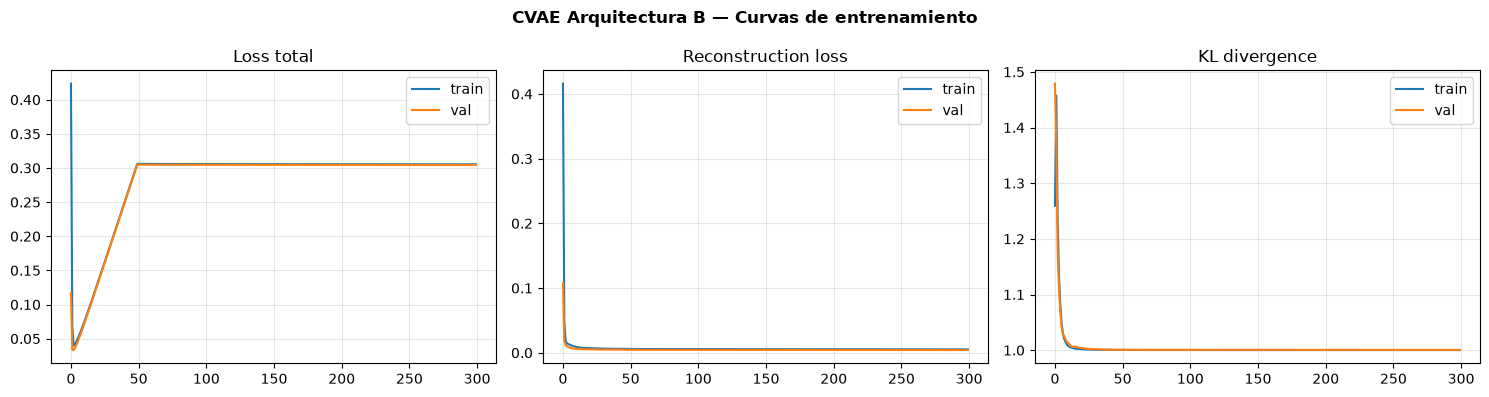

Mejor val loss: 0.3043


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history_b['train_loss'], label='train')
axes[0].plot(history_b['val_loss'],   label='val')
axes[0].set_title('Loss total')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_b['train_recon'], label='train')
axes[1].plot(history_b['val_recon'],   label='val')
axes[1].set_title('Reconstruction loss')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(history_b['train_kl'], label='train')
axes[2].plot(history_b['val_kl'],   label='val')
axes[2].set_title('KL divergence')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle('CVAE Arquitectura B — Curvas de entrenamiento', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cvae_b_training.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Mejor val loss: {history_b["best_val_loss"]:.4f}')

### Diagnostico: colapso de condicionamiento

Antes de mirar las metricas de generacion, comparamos dos formas de decodificar en validacion: usando el `mu` real del encoder (que vio el `x` verdadero) contra usando un `z` muestreado del prior `N(0,1)` (lo que realmente pasa al generar escenarios, ya que ahi no hay ningun `x` real disponible, solo `c`).

Si el error con `z` del prior es mucho mas alto que con el `mu` del encoder, el decoder esta dependiendo de informacion filtrada por `z` en vez de aprender de `c` — y por lo tanto la generacion real (la que importa para el proyecto) va a fallar aunque la reconstruccion de entrenamiento se vea bien.

In [7]:
gap_b = posterior_prior_gap(model_b, X_val, C_val, x_scaler_b, device=DEVICE)
print(f'MAE decodificando con mu del encoder (posterior): {gap_b["mae_posterior"]:.1f} MWh')
print(f'MAE decodificando con z del prior (generacion real): {gap_b["mae_prior"]:.1f} MWh')
print(f'Relacion prior/posterior: {gap_b["gap_ratio"]:.1f}x')

MAE decodificando con mu del encoder (posterior): 31.6 MWh
MAE decodificando con z del prior (generacion real): 119.7 MWh
Relacion prior/posterior: 3.8x


### Eleccion final de hiperparametros

Se probaron cuatro configuraciones sobre validacion antes de fijar esta: la version con `beta=1.0` y `free_bits=0.5` da el mejor MAE (68.6 MWh) pero una cobertura P5-P95 baja (66.8%, lejos del ~90% buscado) y una diversidad de escenarios muy chica (0.042). Tambien se probo agregar dropout sobre `c` en el encoder y el decoder para forzar que el modelo dependa menos de la condicion — esa variante empeoro todo (MAE 217.6 MWh, mas del triple, incluso decodificando con el `mu` real del encoder): el dropout no hizo que el modelo aprendiera a usar mejor `z`, simplemente lo volvio mas ruidoso en general.

La configuracion final (`beta=0.3`, `free_bits=1.0`) prioriza cobertura y diversidad de escenarios sobre el MAE puntual: sube la cobertura a ~85% y la diversidad a 0.066, a cambio de un MAE mayor que la version mas agresiva de regularizacion. Es una decision deliberada — para un modelo generativo que se va a evaluar por coverage/sharpness/MMD (no solo por error puntual), preferimos escenarios mejor calibrados aunque el punto central sea menos preciso.

## 4. Evaluacion en validacion

In [8]:
provinces_val = data_b['provinces_val']

metrics_val_b, scenarios_val_b = full_evaluation(
    model_b, X_val, C_val, x_scaler_b,
    n_scenarios=500, device=DEVICE,
    provinces=provinces_val, architecture='B'
)

print('Metricas en validacion:')
print(f'  MAE global:      {metrics_val_b["mae_global"]:.1f} MWh')
print(f'  RMSE global:     {metrics_val_b["rmse_global"]:.1f} MWh')
print(f'  MAPE energia:    {metrics_val_b["mape_energy"]:.2f}%')
print(f'  Coverage P5-P95: {metrics_val_b["coverage"]:.1f}%')
print(f'  Sharpness:       {metrics_val_b["sharpness"]:.1f} MWh')
print(f'  Diversity ratio: {metrics_val_b["diversity_ratio"]:.3f}')
print(f'  MMD:             {metrics_val_b["mmd"]:.4f}')

Generando 500 escenarios para 8052 muestras...
Calculando metricas...
Metricas en validacion:
  MAE global:      95.3 MWh
  RMSE global:     272.1 MWh
  MAPE energia:    13.76%
  Coverage P5-P95: 82.8%
  Sharpness:       315.5 MWh
  Diversity ratio: 0.061
  MMD:             0.0040


In [9]:
metrics_val_b['per_province']

,provincia,mae_mwh,coverage,sharpness
0,buenos_aires,1004.1,75.5,3042.399902
1,chubut,132.9,70.9,367.100006
2,chaco,114.8,45.5,188.699997
3,santa_fe,103.5,91.5,488.500000
4,cordoba,100.8,95.8,569.299988
5,entre_rios,77.9,75.9,249.899994
6,corrientes,72.8,69.9,184.899994
7,tucuman,71.1,62.3,180.600006
8,mendoza,69.5,87.1,279.000000
9,sgo_del_estero,51.9,84.9,188.000000


**Como interpretar estas metricas con cuidado**

- Un coverage mas alto que el de CVAE-A o KDE no implica automaticamente que CVAE-B sea 'mejor' en terminos globales — puede simplemente reflejar que, al modelar una sola provincia a la vez con menos dimensiones, es mas facil ensanchar la banda P5-P95 relativa a esa escala.
- Un sharpness mayor puede indicar bandas demasiado amplias (poco informativas), no necesariamente mejor calibracion — hay que mirarlo siempre junto al coverage, nunca solo.
- El RMSE de CVAE-B no es comparable en magnitud absoluta con el de CVAE-A/KDE/VAE: esta en unidades de MWh de una sola provincia (24 dimensiones), mientras que los otros tres promedian sobre las 22 provincias juntas (528 dimensiones) — una diferencia de escala, no necesariamente de calidad del modelo.

## 5. Visualizacion de escenarios generados

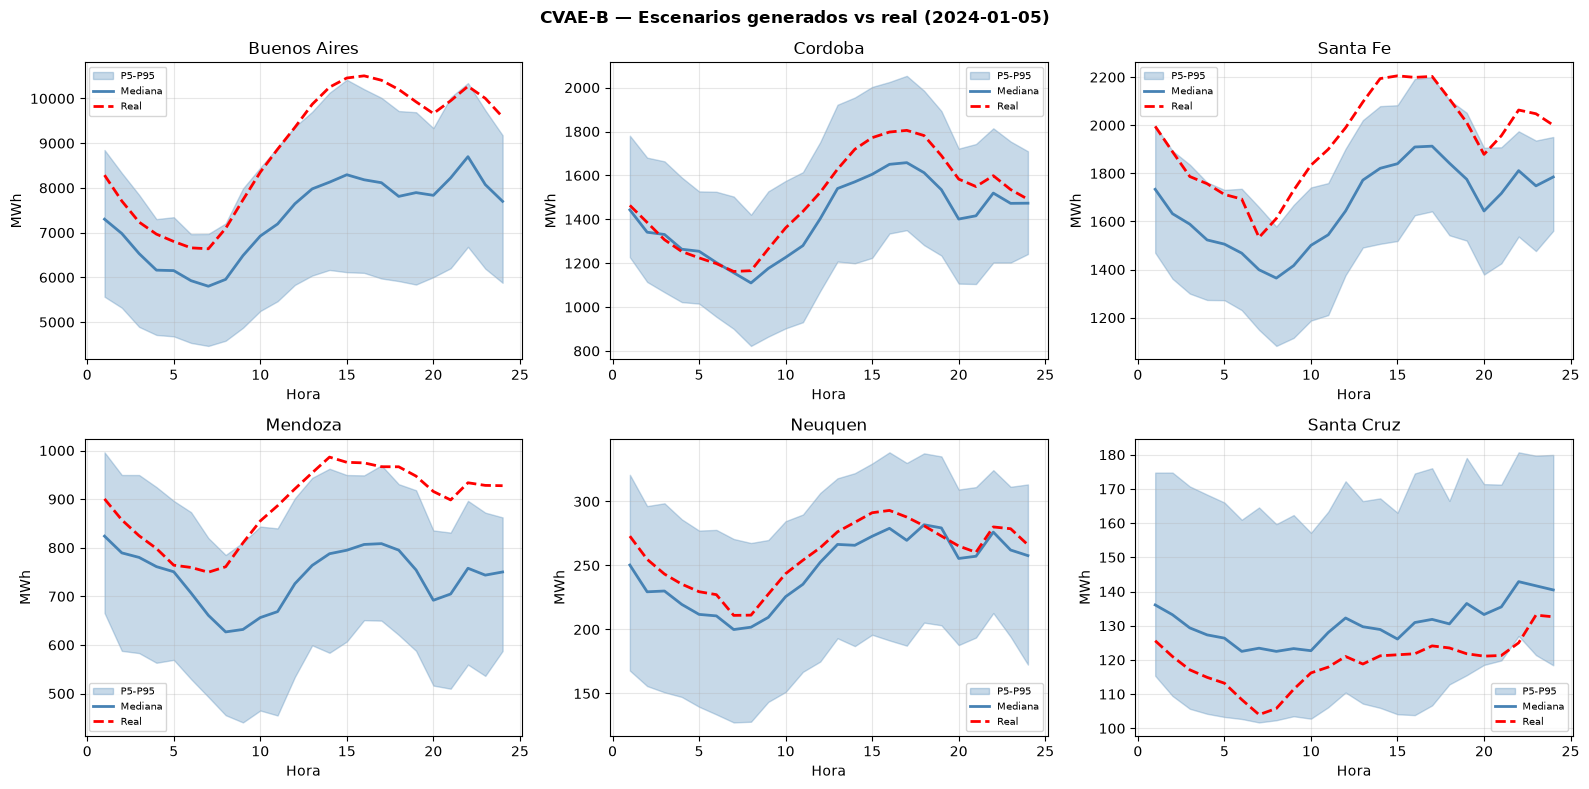

In [17]:
# Visualizar escenarios para 6 provincias en un dia de val
provinces_to_show = ['buenos_aires', 'cordoba', 'santa_fe', 'mendoza', 'neuquen', 'santa_cruz']
PROVINCE_ORDER = [
    'buenos_aires', 'catamarca', 'chaco', 'chubut', 'cordoba',
    'corrientes', 'entre_rios', 'formosa', 'jujuy', 'la_pampa',
    'la_rioja', 'mendoza', 'misiones', 'neuquen', 'rio_negro',
    'salta', 'san_juan', 'san_luis', 'santa_cruz', 'santa_fe',
    'sgo_del_estero', 'tucuman',
]

# En arch B, una fecha tiene 22 filas (una por provincia)
# Tomamos el primer dia del val set
first_date = pd.to_datetime(data_b['dates_val'])[100]
val_dates_ts = pd.to_datetime(data_b['dates_val'])

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, prov in zip(axes.flat, provinces_to_show):
    mask = (val_dates_ts == first_date) & (provinces_val == prov)
    if not mask.any():
        continue
    idx = np.where(mask)[0][0]
    real_mwh = x_scaler_b.inverse_transform(X_val[idx:idx+1]).flatten()
    scen_mwh = np.stack([
        x_scaler_b.inverse_transform(scenarios_val_b[idx, s:s+1, :]).flatten()
        for s in range(scenarios_val_b.shape[1])
    ])
    p5  = np.percentile(scen_mwh, 5,  axis=0)
    p50 = np.percentile(scen_mwh, 50, axis=0)
    p95 = np.percentile(scen_mwh, 95, axis=0)
    horas = range(1, 25)
    ax.fill_between(horas, p5, p95, alpha=0.3, color='steelblue', label='P5-P95')
    ax.plot(horas, p50,      color='steelblue', linewidth=2, label='Mediana')
    ax.plot(horas, real_mwh, color='red',       linewidth=2, label='Real', linestyle='--')
    ax.set_title(prov.replace('_', ' ').title())
    ax.set_xlabel('Hora')
    ax.set_ylabel('MWh')
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

plt.suptitle(f'CVAE-B — Escenarios generados vs real ({first_date.date()})', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cvae_b_scenarios.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Resultado final en test

In [11]:
metrics_test_b, _ = full_evaluation(
    model_b, X_test, C_test, x_scaler_b,
    n_scenarios=500, device=DEVICE,
    provinces=provinces_test, architecture='B'
)

print('=== RESULTADO FINAL EN TEST — CVAE ARQUITECTURA B ===')
print(f'  MAE global:      {metrics_test_b["mae_global"]:.1f} MWh')
print(f'  RMSE global:     {metrics_test_b["rmse_global"]:.1f} MWh')
print(f'  MAPE energia:    {metrics_test_b["mape_energy"]:.2f}%')
print(f'  Coverage P5-P95: {metrics_test_b["coverage"]:.1f}%')
print(f'  Sharpness:       {metrics_test_b["sharpness"]:.1f} MWh')
print(f'  Diversity ratio: {metrics_test_b["diversity_ratio"]:.3f}')
print(f'  MMD:             {metrics_test_b["mmd"]:.4f}')

Generando 500 escenarios para 10670 muestras...
Calculando metricas...
=== RESULTADO FINAL EN TEST — CVAE ARQUITECTURA B ===
  MAE global:      108.1 MWh
  RMSE global:     318.5 MWh
  MAPE energia:    14.38%
  Coverage P5-P95: 81.6%
  Sharpness:       309.2 MWh
  Diversity ratio: 0.059
  MMD:             0.0040


In [12]:
results_b = {
    'model': 'cvae_architecture_b',
    'val': {
        'mae_global':      float(round(metrics_val_b['mae_global'], 2)),
        'rmse_global':     float(round(metrics_val_b['rmse_global'], 2)),
        'mape_energy':     float(round(metrics_val_b['mape_energy'], 4)),
        'coverage':        float(round(metrics_val_b['coverage'], 2)),
        'sharpness':       float(round(metrics_val_b['sharpness'], 2)),
        'diversity_ratio': float(round(metrics_val_b['diversity_ratio'], 4)),
        'mmd':             float(round(metrics_val_b['mmd'], 6)),
    },
    'test': {
        'mae_global':      float(round(metrics_test_b['mae_global'], 2)),
        'rmse_global':     float(round(metrics_test_b['rmse_global'], 2)),
        'mape_energy':     float(round(metrics_test_b['mape_energy'], 4)),
        'coverage':        float(round(metrics_test_b['coverage'], 2)),
        'sharpness':       float(round(metrics_test_b['sharpness'], 2)),
        'diversity_ratio': float(round(metrics_test_b['diversity_ratio'], 4)),
        'mmd':             float(round(metrics_test_b['mmd'], 6)),
    },
}

with open(RESULTS_DIR / 'cvae_b_metrics.json', 'w') as f:
    json.dump(results_b, f, indent=2)
print('Metricas guardadas en results/cvae_b_metrics.json')


Metricas guardadas en results/cvae_b_metrics.json


## 7. Conclusion — CVAE Arquitectura B

CVAE-B es un **experimento complementario**, no una alternativa directa a CVAE-A: cambia la unidad de muestra a provincia-dia (24 dimensiones) para poder usar indicadores socioeconomicos que varian entre muestras, a costa de perder la generacion conjunta de las 22 provincias en un mismo dia.

Si estos resultados entran en la tabla final del informe, deben marcarse como arquitectura alternativa, con una nota aclarando que MAE/RMSE/sharpness/MMD de CVAE-B se calculan en un espacio de 24 dimensiones por provincia-dia, mientras que CVAE-A, KDE y VAE se calculan en 528 dimensiones por dia-sistema — no son la misma escala y no deberian leerse como si compitieran en la misma tabla sin esa aclaracion.

La pregunta que este experimento responde no es "¿es mejor que CVAE-A?", sino "¿ayuda representar cada provincia por separado, con sus propios indicadores socioeconomicos, a calibrar mejor los perfiles locales?" — y ahi si es comparable contra el Historical Mean y contra el desglose por provincia de CVAE-A.

## 8. Robustez frente a ruido en variables climaticas

Mismo experimento que en CVAE-A: se agrega ruido gaussiano de distintos niveles
solo a las variables climaticas de `C_test`, sin tocar calendario ni indicadores
socioeconomicos.

En Arquitectura B el experimento tiene una dimension adicional: el vector `c` incluye
indicadores socioeconomicos ademas del clima. Al agregar ruido solo al clima, se puede
evaluar si los indicadores actuan como ancla estabilizadora — el modelo puede
apoyarse en la informacion estructural de la provincia cuando el clima es incierto.

In [13]:
# Identificar indices de columnas climaticas en C_test para Arquitectura B
# En preprocessing_b.py el orden de c es: [binary | scaled(ordinal + climate + socioeco)]
with open(SPLITS_DIR / 'b_meta.pkl', 'rb') as f:
    b_meta = pickle.load(f)

cols_to_scale = b_meta['cols_to_scale']  # ordinal + climate + socioeco
binary_cols   = b_meta['binary_cols']    # es_feriado

from preprocessing_b import CLIMATE_FEATURES, CALENDAR_FEATURES, SOCIOECO_FEATURES

n_binary  = len(binary_cols)
n_ordinal = len([c for c in cols_to_scale if c in ['mes', 'dia_semana']])
n_climate = len([c for c in cols_to_scale if c in CLIMATE_FEATURES])

climate_start = n_binary + n_ordinal
climate_end   = climate_start + n_climate

print(f'Columnas en C_test: {C_test.shape[1]}')
print(f'Columnas binarias:   {n_binary} (es_feriado)')
print(f'Columnas ordinales:  {n_ordinal} (mes, dia_semana)')
print(f'Columnas climaticas: {n_climate} (indices {climate_start} a {climate_end-1})')
print(f'Columnas socioeco:   {len(SOCIOECO_FEATURES)} (no se perturban)')

Columnas en C_test: 19
Columnas binarias:   1 (es_feriado)
Columnas ordinales:  2 (mes, dia_semana)
Columnas climaticas: 12 (indices 3 a 14)
Columnas socioeco:   4 (no se perturban)


In [14]:
NOISE_LEVELS = [0.00, 0.05, 0.10, 0.20, 0.30]

robustness_results_b = []

for noise_std in NOISE_LEVELS:
    print(f'noise_std={noise_std:.2f}...')

    C_noisy = C_test.copy()
    if noise_std > 0:
        np.random.seed(42)
        C_noisy[:, climate_start:climate_end] += np.random.normal(
            0, noise_std, C_noisy[:, climate_start:climate_end].shape
        )

    metrics, _ = full_evaluation(
        model_b, X_test, C_noisy, x_scaler_b,
        n_scenarios=500, device=DEVICE,
        provinces=provinces_test, architecture='B',
    )

    robustness_results_b.append({
        'noise_std':       noise_std,
        'mae_global':      float(round(metrics['mae_global'], 2)),
        'rmse_global':     float(round(metrics['rmse_global'], 2)),
        'coverage':        float(round(metrics['coverage'], 2)),
        'sharpness':       float(round(metrics['sharpness'], 2)),
        'mmd':             float(round(metrics['mmd'], 6)),
        'diversity_ratio': float(round(metrics['diversity_ratio'], 4)),
    })

df_robustness_b = pd.DataFrame(robustness_results_b)
print('\nResultados:')
print(df_robustness_b.to_string(index=False))

noise_std=0.00...
Generando 500 escenarios para 10670 muestras...
Calculando metricas...
noise_std=0.05...
Generando 500 escenarios para 10670 muestras...
Calculando metricas...
noise_std=0.10...
Generando 500 escenarios para 10670 muestras...
Calculando metricas...
noise_std=0.20...
Generando 500 escenarios para 10670 muestras...
Calculando metricas...
noise_std=0.30...
Generando 500 escenarios para 10670 muestras...
Calculando metricas...

Resultados:
 noise_std  mae_global  rmse_global  coverage  sharpness   mmd  diversity_ratio
      0.00      108.03       318.57     81.64 309.290009 0.004           0.0587
      0.05      108.74       321.03     81.45 309.390015 0.004           0.0587
      0.10      110.65       327.58     80.85 309.130005 0.004           0.0586
      0.20      117.39       349.29     78.45 308.239990 0.004           0.0584
      0.30      127.48       381.85     75.43 306.209991 0.004           0.0581


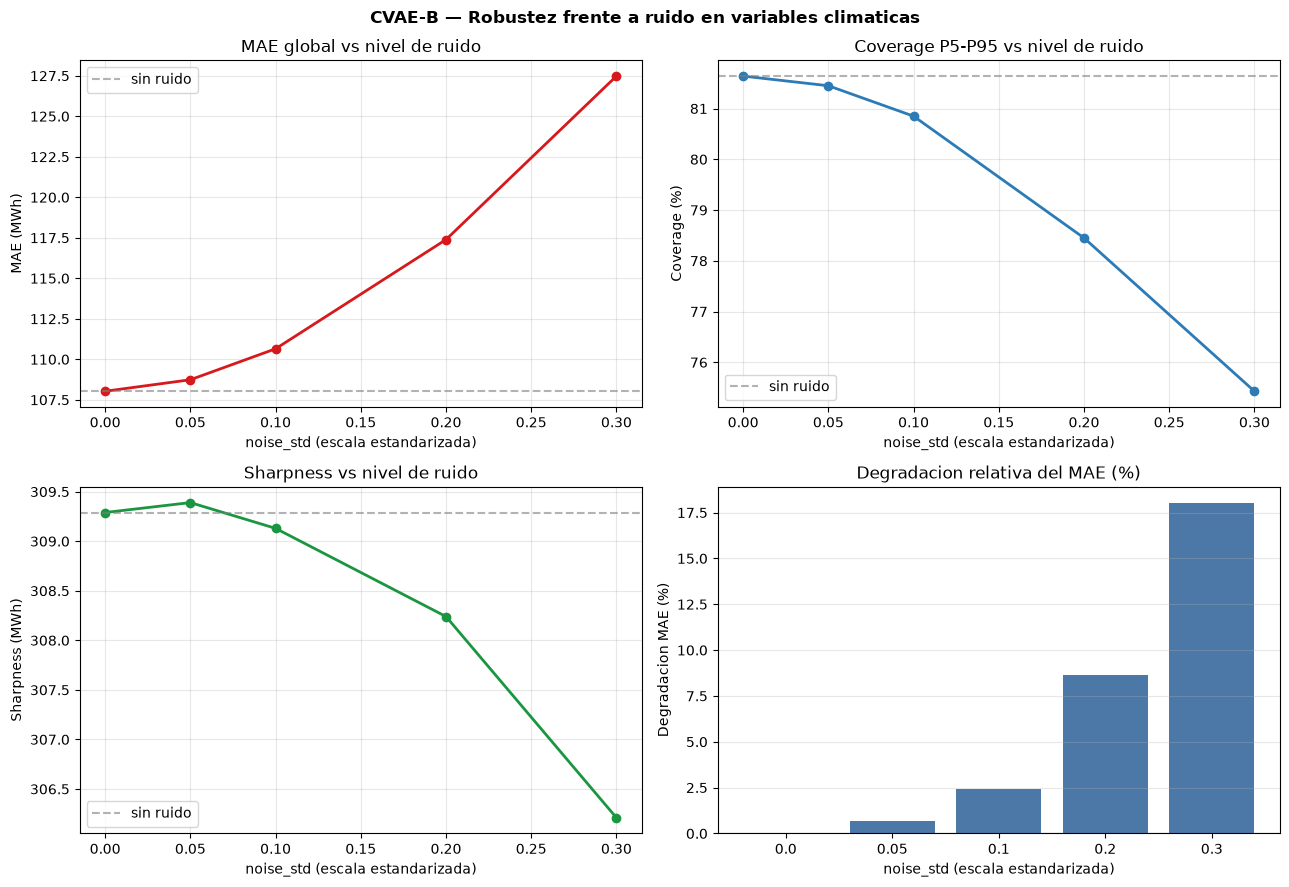

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0,0].plot(df_robustness_b['noise_std'], df_robustness_b['mae_global'],
               marker='o', color='#d7191c', linewidth=2)
axes[0,0].axhline(df_robustness_b.loc[0,'mae_global'], linestyle='--',
                   color='gray', alpha=0.6, label='sin ruido')
axes[0,0].set_title('MAE global vs nivel de ruido')
axes[0,0].set_xlabel('noise_std (escala estandarizada)')
axes[0,0].set_ylabel('MAE (MWh)')
axes[0,0].legend()
axes[0,0].grid(alpha=0.3)

axes[0,1].plot(df_robustness_b['noise_std'], df_robustness_b['coverage'],
               marker='o', color='#2c7bb6', linewidth=2)
axes[0,1].axhline(df_robustness_b.loc[0,'coverage'], linestyle='--',
                   color='gray', alpha=0.6, label='sin ruido')
axes[0,1].set_title('Coverage P5-P95 vs nivel de ruido')
axes[0,1].set_xlabel('noise_std (escala estandarizada)')
axes[0,1].set_ylabel('Coverage (%)')
axes[0,1].legend()
axes[0,1].grid(alpha=0.3)

axes[1,0].plot(df_robustness_b['noise_std'], df_robustness_b['sharpness'],
               marker='o', color='#1a9641', linewidth=2)
axes[1,0].axhline(df_robustness_b.loc[0,'sharpness'], linestyle='--',
                   color='gray', alpha=0.6, label='sin ruido')
axes[1,0].set_title('Sharpness vs nivel de ruido')
axes[1,0].set_xlabel('noise_std (escala estandarizada)')
axes[1,0].set_ylabel('Sharpness (MWh)')
axes[1,0].legend()
axes[1,0].grid(alpha=0.3)

mae_base_b   = df_robustness_b.loc[0, 'mae_global']
degradacion_b = (df_robustness_b['mae_global'] - mae_base_b) / mae_base_b * 100
axes[1,1].bar(df_robustness_b['noise_std'].astype(str), degradacion_b,
              color='#4c78a8')
axes[1,1].axhline(0, color='gray', linewidth=0.8)
axes[1,1].set_title('Degradacion relativa del MAE (%)')
axes[1,1].set_xlabel('noise_std (escala estandarizada)')
axes[1,1].set_ylabel('Degradacion MAE (%)')
axes[1,1].grid(axis='y', alpha=0.3)

plt.suptitle('CVAE-B — Robustez frente a ruido en variables climaticas', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'cvae_b_robustness.png', dpi=150, bbox_inches='tight')
plt.show()

### Interpretacion

A diferencia de CVAE-A, en esta arquitectura los indicadores socioeconomicos
permanecen sin perturbar. Si el modelo es mas robusto que CVAE-A al mismo nivel
de ruido, podria indicar que los indicadores actuan como ancla estructural — el
modelo sabe que es Buenos Aires por su poblacion e industria aunque el clima
reportado tenga error.

Si la degradacion es similar a CVAE-A, el modelo depende principalmente del clima
para generar y los indicadores no estabilizan la generacion ante incertidumbre.

Comparar los resultados de robustez entre A y B es en si mismo un hallazgo sobre
el rol de los indicadores socioeconomicos en la arquitectura provincial.

In [16]:
with open(RESULTS_DIR / 'cvae_b_robustness.json', 'w') as f:
    json.dump(robustness_results_b, f, indent=2)
print('Resultados guardados en results/cvae_b_robustness.json')

Resultados guardados en results/cvae_b_robustness.json


## Interpretacion — Robustez frente a ruido climatico (CVAE-B)

Este experimento replica el analisis de robustez de CVAE-A sobre la Arquitectura B,
con una diferencia clave: el vector `c` de CVAE-B incluye indicadores socioeconomicos
(poblacion, PBG per capita, participacion industrial, superficie) que no se perturban.
Esto permite evaluar si esos indicadores actuan como ancla estructural cuando el clima
tiene error.

**Resultado principal: CVAE-B es significativamente menos robusto que CVAE-A.**

Con noise_std=0.10, el MAE sube de 108.03 a 110.65 MWh — una degradacion del 2.4%,
frente al 0.2% observado en CVAE-A con el mismo nivel de ruido. Con noise_std=0.30
la degradacion llega al 18%, mientras que CVAE-A solo se degrada un 1.9%.

| noise_std | MAE (MWh) | Degradacion MAE | Coverage (%) | Sharpness (MWh) |
|---|---|---|---|---|
| 0.00 | 108.03 | — | 81.6 | 309.3 |
| 0.05 | 108.74 | +0.7% | 81.5 | 309.4 |
| 0.10 | 110.65 | +2.4% | 80.9 | 309.1 |
| 0.20 | 117.39 | +8.7% | 78.5 | 308.2 |
| 0.30 | 127.48 | +18.0% | 75.4 | 306.2 |

**Los indicadores socioeconomicos no actuan como ancla estabilizadora.**

Si los indicadores ayudaran al modelo a mantener su calidad ante clima incierto,
esperariamos que CVAE-B fuera mas robusto que CVAE-A — el modelo podria apoyarse
en la informacion estructural de la provincia cuando el clima tiene error. Sin embargo,
ocurre lo contrario: CVAE-B se degrada aproximadamente 10 veces mas rapido que CVAE-A
ante el mismo nivel de perturbacion climatica.

La explicacion es que CVAE-B depende mas del clima porque modela una sola provincia
a la vez con x de 24 dimensiones. En esa arquitectura, el clima de la provincia es
la principal fuente de variacion entre dias, y el modelo lo aprendio como feature
central. Cuando el clima se perturba, no hay otra fuente de informacion temporal
que compense.

CVAE-A, en cambio, modela el sistema completo en 528 dimensiones. La mayor parte
de la variacion entre dias esta capturada en la estructura conjunta del sistema,
lo que hace al modelo menos dependiente de las variables climaticas individuales.

**Implicacion operacional**

CVAE-B es menos apto que CVAE-A para uso con forecasts meteorologicos imperfectos.
Con un error de pronostico tipico de 24 horas (noise_std ≈ 0.05-0.10), la degradacion
del MAE es del 0.7-2.4% — aceptable pero notoriamente mayor que en CVAE-A.
Para aplicaciones donde el clima viene de un forecast, CVAE-A es la arquitectura
mas confiable.

**Comparacion directa A vs B ante ruido climatico**

| noise_std | Degradacion MAE — CVAE-A | Degradacion MAE — CVAE-B |
|---|---|---|
| 0.05 | +0.0% | +0.7% |
| 0.10 | +0.2% | +2.4% |
| 0.20 | +0.9% | +8.7% |
| 0.30 | +1.9% | +18.0% |

Esta comparacion es uno de los hallazgos mas concretos del trabajo: las dos
arquitecturas no son intercambiables. CVAE-A es mas robusto operacionalmente;
CVAE-B es mas interpretable y permite incorporar caracteristicas provinciales,
pero a costa de mayor sensibilidad al clima de entrada.